<a href="https://colab.research.google.com/github/mwahk3ymer/Natach3r/blob/main/MScFE_652_Portfolio_Management_Group_19726_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

[*********************100%***********************]  10 of 10 completed


In-sample weeks: 108

--- Max-Sharpe (tangency) portfolio, weekly data ---
Expected return (ann.): 38.7322%
Volatility      (ann.): 19.0517%
Sharpe ratio    (ann.): 1.7768

Weights:
  AAPL   0.3949
  GS     0.3549
  MRK    0.1645
  BAC    0.0857
  LLY    0.0000
  XOM    0.0000
  META   0.0000
  GOOG   0.0000
  TSLA   0.0000
  WMT    0.0000


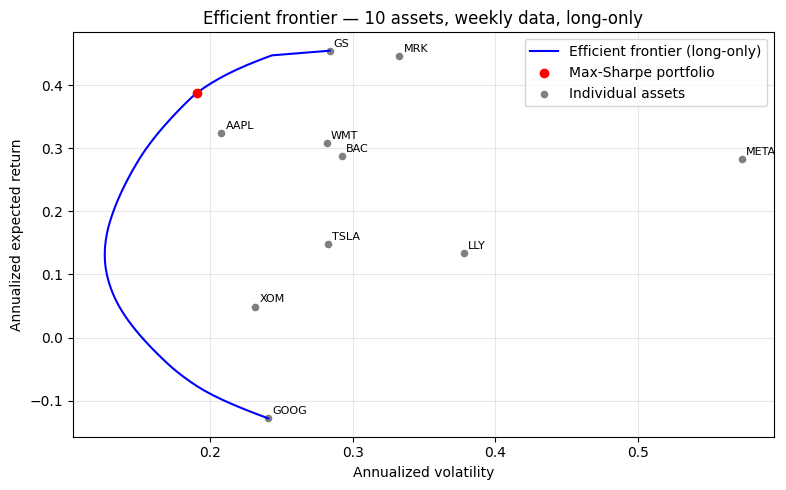

In [ ]:
import numpy as np
import pandas as pd
import yfinance as yf
import cvxpy as cp
import matplotlib.pyplot as plt
from scipy.optimize import minimize

# ---------- 1. Data ----------
tickers = ["TSLA","WMT","BAC","GS","LLY","MRK","GOOG","META","AAPL","XOM"]
start, end = "2023-09-01", "2025-12-31"   # pull both windows in one go
raw = yf.download(tickers, start=start, end=end, auto_adjust=True)["Close"]

# Weekly (Friday) close, then weekly log returns
weekly = raw.resample("W-FRI").last()
weekly = weekly.dropna(how="any")          # align on common trading weeks
rets = np.log(weekly).diff().dropna()

# In-sample window
in_sample = rets.loc["2023-09-01":"2025-09-30"]
print("In-sample weeks:", len(in_sample))

mu_w  = in_sample.mean().values            # weekly mean
Sigma_w = in_sample.cov().values           # weekly covariance
n = len(tickers)

# Annualized for reporting
mu_ann    = mu_w * 52
Sigma_ann = Sigma_w * 52
vol_ann   = np.sqrt(np.diag(Sigma_ann))

# ---------- 2. Efficient frontier via cvxpy ----------
def min_var_for_target(mu, Sigma, target, w_max=None):
    """Min variance s.t. sum w = 1, w >= 0, mu'w = target (optional w <= w_max)."""
    n = len(mu)
    w = cp.Variable(n)
    constraints = [cp.sum(w) == 1, w >= 0, mu @ w == target]
    if w_max is not None:
        constraints.append(w <= w_max)
    prob = cp.Problem(cp.Minimize(cp.quad_form(w, Sigma)), constraints)
    prob.solve(solver=cp.OSQP)   # QP solver
    if w.value is None or prob.status not in ("optimal","optimal_inaccurate"):
        return None
    return w.value

# Grid of target returns (weekly units) between min-var return and max asset mean
r_min = mu_w.min()
r_max = mu_w.max()
targets = np.linspace(r_min, r_max, 80)

frontier_vol, frontier_ret, frontier_w = [], [], []
for t in targets:
    w_opt = min_var_for_target(mu_w, Sigma_w, t)
    if w_opt is not None:
        frontier_w.append(w_opt)
        frontier_ret.append(mu_w @ w_opt)
        frontier_vol.append(np.sqrt(w_opt @ Sigma_w @ w_opt))

frontier_vol = np.array(frontier_vol)
frontier_ret = np.array(frontier_ret)
frontier_w   = np.array(frontier_w)

# ---------- 3. Max-Sharpe (tangency) portfolio ----------
# Weekly risk-free: convert annual 3m T-bill (~5% in period) to weekly
rf_ann = 0.05
rf_w   = (1 + rf_ann)**(1/52) - 1

def neg_sharpe(w, mu, Sigma, rf):
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    return -(port_ret - rf) / port_vol

cons = [{"type":"eq","fun":lambda w: np.sum(w)-1}]
bnds = [(0,1)]*n
w0 = np.ones(n)/n
res = minimize(neg_sharpe, w0, args=(mu_w,Sigma_w,rf_w),
               method="SLSQP", bounds=bnds, constraints=cons,
               options={"ftol":1e-12,"maxiter":1000})
w_tangency = res.x

port_ret_w = mu_w @ w_tangency
port_vol_w = np.sqrt(w_tangency @ Sigma_w @ w_tangency)
sharpe_w   = (port_ret_w - rf_w)/port_vol_w

# Annualized reporting
print("\n--- Max-Sharpe (tangency) portfolio, weekly data ---")
print(f"Expected return (ann.): {port_ret_w*52:.4%}")
print(f"Volatility      (ann.): {port_vol_w*np.sqrt(52):.4%}")
print(f"Sharpe ratio    (ann.): {sharpe_w*np.sqrt(52):.4f}")
print("\nWeights:")
for t, w in sorted(zip(tickers, w_tangency), key=lambda x:-x[1]):
    print(f"  {t:5s} {w:7.4f}")

# ---------- 4. Plot frontier + tangency ----------
plt.figure(figsize=(8,5))
plt.plot(frontier_vol*np.sqrt(52), frontier_ret*52, 'b-', label="Efficient frontier (long-only)")
plt.scatter(port_vol_w*np.sqrt(52), port_ret_w*52, color='red', zorder=5,
            label="Max-Sharpe portfolio")
plt.scatter(vol_ann, mu_ann, color='grey', s=20, label="Individual assets")
for t, v, m in zip(tickers, vol_ann, mu_ann):
    plt.annotate(t, (v, m), fontsize=8, xytext=(3,3), textcoords='offset points')
plt.xlabel("Annualized volatility"); plt.ylabel("Annualized expected return")
plt.title("Efficient frontier — 10 assets, weekly data, long-only")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout(); plt.show()

In [ ]:
# ---------- Step 2: Optimization with 18% Cap ----------

# Define the constraint: no weight can exceed 0.18
def neg_sharpe_capped(w, mu, Sigma, rf):
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    return -(port_ret - rf) / port_vol

# Constraints: sum to 1
cons_capped = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]

# Bounds: 0 <= w_i <= 0.18
bnds_capped = [(0, 0.18)] * n

# Initial guess: equal weight (which satisfies the cap)
w0_capped = np.ones(n) / n

# Run the optimizer
res_capped = minimize(neg_sharpe_capped, w0_capped, args=(mu_w, Sigma_w, rf_w),
                      method="SLSQP", bounds=bnds_capped, constraints=cons_capped,
                      options={"ftol": 1e-12, "maxiter": 1000})

w_step2 = res_capped.x

# Calculate Performance Metrics
port_ret_step2 = mu_w @ w_step2
port_vol_step2 = np.sqrt(w_step2 @ Sigma_w @ w_step2)
sharpe_step2 = (port_ret_step2 - rf_w) / port_vol_step2

# Print Results
print("\n--- Step 2: Constrained Portfolio (Max 18% per asset) ---")
print(f"Expected return (ann.): {port_ret_step2*52:.4%}")
print(f"Volatility      (ann.): {port_vol_step2*np.sqrt(52):.4%}")
print(f"Sharpe ratio    (ann.): {sharpe_step2*np.sqrt(52):.4f}")
print("\nWeights:")
for t, w in sorted(zip(tickers, w_step2), key=lambda x: -x[1]):
    print(f"  {t:5s} {w:7.4f}")


--- Step 2: Constrained Portfolio (Max 18% per asset) ---
Expected return (ann.): 33.5238%
Volatility      (ann.): 18.2044%
Sharpe ratio    (ann.): 1.5734

Weights:
  BAC    0.1800
  GS     0.1800
  MRK    0.1800
  AAPL   0.1800
  WMT    0.1800
  XOM    0.0688
  LLY    0.0312
  GOOG   0.0000
  META   0.0000
  TSLA   0.0000


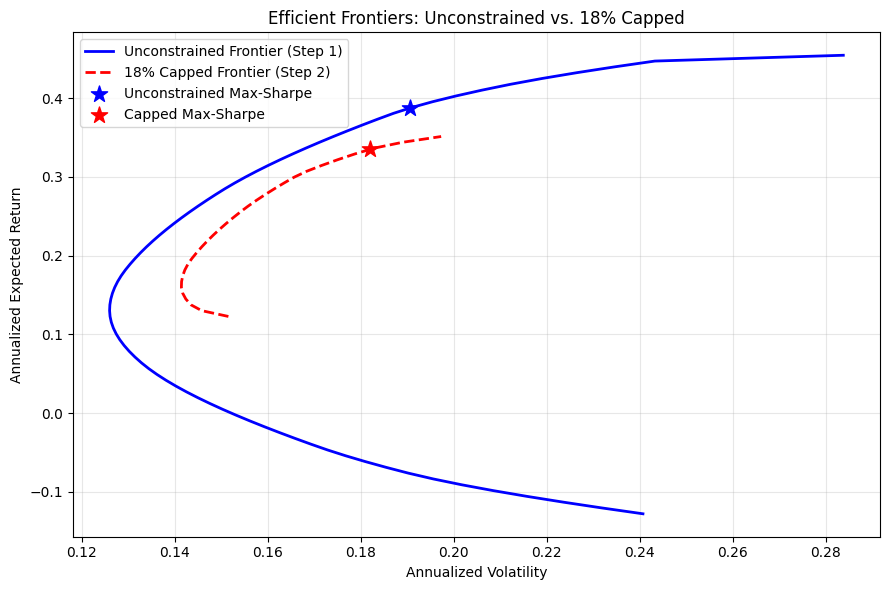

In [ ]:
# ---------- Step 3: Plotting Both Efficient Frontiers ----------

# We will use the min_var_for_target function from Step 1,
# but add the w_max=0.18 constraint for the second frontier.

frontier_vol_capped, frontier_ret_capped = [], []

# Note: The max possible return is now bounded by the 18% cap.
# We can use the same target grid, but the optimizer will fail for targets
# that are impossible under the 18% cap.
targets_capped = np.linspace(mu_w.min(), mu_w.max(), 80)

for t in targets_capped:
    # Pass w_max=0.18 to the function we defined in Step 1
    w_opt = min_var_for_target(mu_w, Sigma_w, t, w_max=0.18)
    if w_opt is not None:
        frontier_vol_capped.append(np.sqrt(w_opt @ Sigma_w @ w_opt))
        frontier_ret_capped.append(mu_w @ w_opt)

frontier_vol_capped = np.array(frontier_vol_capped)
frontier_ret_capped = np.array(frontier_ret_capped)

# Plotting
plt.figure(figsize=(9,6))

# Unconstrained Frontier (from Step 1)
plt.plot(frontier_vol*np.sqrt(52), frontier_ret*52, 'b-', label="Unconstrained Frontier (Step 1)", linewidth=2)

# Constrained Frontier (Step 2)
plt.plot(frontier_vol_capped*np.sqrt(52), frontier_ret_capped*52, 'r--', label="18% Capped Frontier (Step 2)", linewidth=2)

# Max Sharpe Points
plt.scatter(port_vol_w*np.sqrt(52), port_ret_w*52, color='blue', marker='*', s=150, zorder=5, label="Unconstrained Max-Sharpe")
plt.scatter(port_vol_step2*np.sqrt(52), port_ret_step2*52, color='red', marker='*', s=150, zorder=5, label="Capped Max-Sharpe")

plt.xlabel("Annualized Volatility")
plt.ylabel("Annualized Expected Return")
plt.title("Efficient Frontiers: Unconstrained vs. 18% Capped")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

--- OOS Performance (Oct - Dec 2025) ---
Portfolio 1 (Unconstrained):
  Cumulative Return: 10.42%
  Sharpe Ratio:      2.2378
  Max Drawdown:      -1.19%

Portfolio 2 (18% Capped):
  Cumulative Return: 11.47%
  Sharpe Ratio:      3.0102
  Max Drawdown:      -0.74%


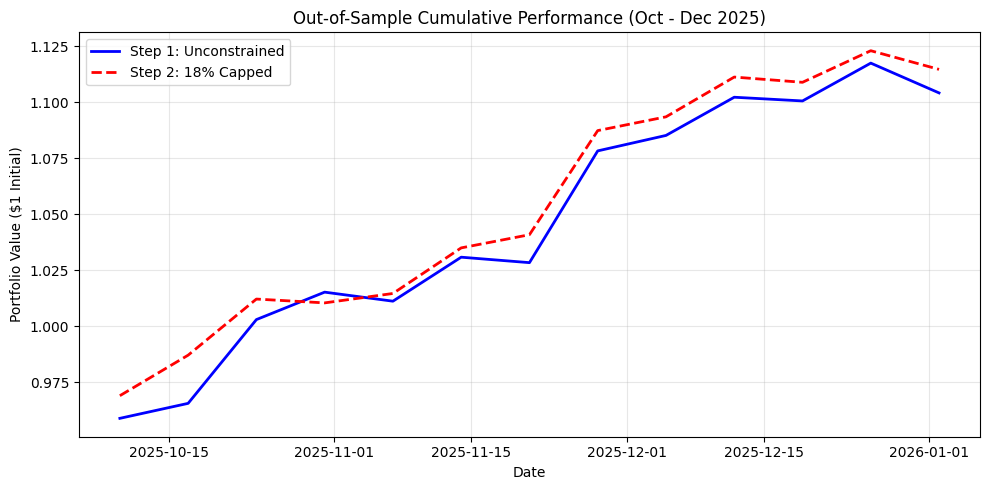

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------- Step 4: Out-of-Sample Performance (Oct 1 - Dec 31, 2025) ----------

# 1. Isolate the Out-of-Sample Data
weekly_oos = raw.loc["2025-10-01":"2025-12-31"].resample("W-FRI").last()
weekly_oos = weekly_oos.dropna(how="any")
rets_oos = np.log(weekly_oos).diff().dropna()

# Convert to numpy array for matrix multiplication
R_oos = rets_oos[tickers].values

# 2. Calculate daily weekly returns for the portfolios
# We use matrix multiplication: (T x 10) dot (10 x 1) = (T x 1)
port_rets_step1 = R_oos @ w_tangency
port_rets_step2 = R_oos @ w_step2

# 3. Performance Metrics Function
def calc_metrics(returns, rf_weekly):
    # Cumulative Return
    cum_ret = np.prod(1 + returns) - 1

    # Annualized Sharpe Ratio (OOS)
    # Mean excess return / std dev of excess return * sqrt(52)
    excess = returns - rf_weekly
    sharpe = (np.mean(excess) / np.std(excess, ddof=1)) * np.sqrt(52)

    # Max Drawdown
    # Create a wealth index starting at 1.0
    wealth_index = np.cumprod(1 + returns)
    running_max = np.maximum.accumulate(wealth_index)
    drawdowns = (wealth_index - running_max) / running_max
    max_dd = drawdowns.min()

    return cum_ret, sharpe, max_dd, wealth_index, drawdowns

# Calculate metrics
cum1, sr1, mdd1, wealth1, dd1 = calc_metrics(port_rets_step1, rf_w)
cum2, sr2, mdd2, wealth2, dd2 = calc_metrics(port_rets_step2, rf_w)

print("--- OOS Performance (Oct - Dec 2025) ---")
print(f"Portfolio 1 (Unconstrained):")
print(f"  Cumulative Return: {cum1:.2%}")
print(f"  Sharpe Ratio:      {sr1:.4f}")
print(f"  Max Drawdown:      {mdd1:.2%}")

print(f"\nPortfolio 2 (18% Capped):")
print(f"  Cumulative Return: {cum2:.2%}")
print(f"  Sharpe Ratio:      {sr2:.4f}")
print(f"  Max Drawdown:      {mdd2:.2%}")

# 4. Plot Cumulative Returns
plt.figure(figsize=(10, 5))
plt.plot(rets_oos.index, wealth1, label="Step 1: Unconstrained", color='blue', linewidth=2)
plt.plot(rets_oos.index, wealth2, label="Step 2: 18% Capped", color='red', linestyle='--', linewidth=2)
plt.title("Out-of-Sample Cumulative Performance (Oct - Dec 2025)")
plt.ylabel("Portfolio Value ($1 Initial)")
plt.xlabel("Date")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
import pandas_datareader.data as web
import pandas as pd
import numpy as np

# 1. Download the DAILY Fama-French 5 factors
# Daily data is reliably hosted and never has 404 issues.
ff_daily = web.DataReader("F-F_Research_Data_5_Factors_2x3_daily", "famafrench", start="2023-09-01", end="2025-09-30")[0]

# 2. Convert percentages to decimals
ff_daily = ff_daily.astype(float) / 100

# 3. Resample to Weekly (Friday) to match your portfolio data
# We compound the daily returns to get weekly returns: (1 + r).prod() - 1
ff_weekly = (1 + ff_daily).resample('W-FRI').prod() - 1

# 4. Extract your in-sample window
ff_in_sample = ff_weekly.loc['2023-09-01':'2025-09-30']

# Rename columns just to be safe
ff_in_sample.columns = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']

print("Fama-French Weekly Data successfully compiled from Daily data:")
print(ff_in_sample.head())

Fama-French Weekly Data successfully compiled from Daily data:
                         Mkt-RF       SMB       HML       RMW       CMA  \
Date                                                                      
2023-08-26/2023-09-01  0.002600  0.008500  0.005800  0.000000 -0.002200   
2023-09-02/2023-09-08 -0.015232 -0.027380 -0.006328 -0.006499 -0.003506   
2023-09-09/2023-09-15 -0.002943 -0.004257  0.013991  0.004653 -0.000924   
2023-09-16/2023-09-22 -0.031488 -0.007413 -0.000325  0.015490  0.006805   
2023-09-23/2023-09-29 -0.005724  0.012640  0.002680  0.006488 -0.009669   

                           RF  
Date                           
2023-08-26/2023-09-01  0.0002  
2023-09-02/2023-09-08  0.0008  
2023-09-09/2023-09-15  0.0010  
2023-09-16/2023-09-22  0.0010  
2023-09-23/2023-09-29  0.0010  


/tmp/ipykernel_1723/4103723246.py:14: FutureWarning: Resampling with a PeriodIndex is deprecated. Cast index to DatetimeIndex before resampling instead.
  ff_weekly = (1 + ff_daily).resample('W-FRI').prod() - 1


In [ ]:
import pandas_datareader.data as web
import pandas as pd
import numpy as np
import statsmodels.api as sm

# 1. Download DAILY Fama-French 5 factors
ff_daily = web.DataReader("F-F_Research_Data_5_Factors_2x3_daily", "famafrench", start="2023-09-01", end="2025-09-30")[0]
ff_daily = ff_daily.astype(float) / 100

# 2. FIX THE WARNING: Convert PeriodIndex to DatetimeIndex
ff_daily.index = ff_daily.index.to_timestamp()

# 3. Resample to Weekly (Friday)
ff_weekly = (1 + ff_daily).resample('W-FRI').prod() - 1
ff_in_sample = ff_weekly.loc['2023-09-01':'2025-09-30']
ff_in_sample.columns = ['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA', 'RF']

# 4. Get the Step 2 portfolio returns (in-sample)
in_sample_assets = rets.loc['2023-09-01':'2025-09-30']
port_rets_in_sample = in_sample_assets[tickers].values @ w_step2
port_rets_series = pd.Series(port_rets_in_sample, index=in_sample_assets.index, name="Port_Ret")

# 5. Merge portfolio returns with FF data
# We do an inner join to ensure we only keep dates where BOTH have data
merged_data = pd.concat([port_rets_series, ff_in_sample], axis=1, join='inner')

# 6. Create Excess Return
merged_data['Excess_Ret'] = merged_data['Port_Ret'] - merged_data['RF']

# 7. Correlation Matrix (Step 4)
print("--- Correlation Matrix of the 5 Factors ---")
print(merged_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']].corr().round(3))

# 8. Train / Test Split (70/30) (Step 5)
split_idx = int(len(merged_data) * 0.70)
train_data = merged_data.iloc[:split_idx]
test_data = merged_data.iloc[split_idx:]

print(f"\nTraining data: {train_data.index.min().date()} to {train_data.index.max().date()} ({len(train_data)} weeks)")
print(f"Testing data:  {test_data.index.min().date()} to {test_data.index.max().date()} ({len(test_data)} weeks)")

# 9. Setup X and y
X_train = train_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]
y_train = train_data['Excess_Ret']
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(test_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])

# 10. OLS and Robust Regression
model_ols = sm.OLS(y_train, X_train_const).fit()
model_robust = sm.OLS(y_train, X_train_const).fit(cov_type='HAC', cov_kwds={'maxlags': 4})

print("\n--- OLS Regression Results (Training Data) ---")
print(model_ols.summary().tables[1])

print("\n--- Robust (HAC) Regression Results (Training Data) ---")
print(model_robust.summary().tables[1])

# 11. Test Data R-squared
y_pred_test = model_ols.predict(X_test_const)
ss_res = np.sum((test_data['Excess_Ret'] - y_pred_test)**2)
ss_tot = np.sum((test_data['Excess_Ret'] - np.mean(test_data['Excess_Ret']))**2)
test_r2 = 1 - (ss_res / ss_tot)

print(f"\nOut-of-Sample (Test) R-squared: {test_r2:.4f}")

--- Correlation Matrix of the 5 Factors ---
        Mkt-RF    SMB    HML    RMW    CMA
Mkt-RF   1.000  0.171 -0.225 -0.471  0.147
SMB      0.171  1.000  0.450 -0.474  0.309
HML     -0.225  0.450  1.000  0.002  0.242
RMW     -0.471 -0.474  0.002  1.000 -0.282
CMA      0.147  0.309  0.242 -0.282  1.000

Training data: 2023-09-08 to 2025-02-07 (75 weeks)
Testing data:  2025-02-14 to 2025-09-26 (33 weeks)

--- OLS Regression Results (Training Data) ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.001      0.366      0.715      -0.002       0.003
Mkt-RF         0.8187      0.064     12.752      0.000       0.691       0.947
SMB           -0.0811      0.083     -0.980      0.330      -0.246       0.084
HML            0.4132      0.080      5.186      0.000       0.254       0.572
RMW           -0.0825      0.124     -0.668      0.506      -0.329       

In [ ]:
# 1. Get the Step 2 portfolio returns (in-sample)
# Assuming 'rets' is your DataFrame of asset returns from Part 1
in_sample_assets = rets.loc['2023-09-01':'2025-09-30']

# Calculate Step 2 portfolio returns (w_step2 @ asset_returns)
port_rets_in_sample = in_sample_assets[tickers].values @ w_step2
port_rets_series = pd.Series(port_rets_in_sample, index=in_sample_assets.index, name="Port_Ret")

# 2. Merge the portfolio returns with FF data
# We use forward-fill to match our Friday dates to the most recent FF Wednesday date
merged_data = pd.concat([port_rets_series, ff_in_sample], axis=1).dropna()
merged_data = merged_data.ffill() # Align FF dates to our Friday dates

# 3. Create the Dependent Variable: Excess Portfolio Return
# E[Rp] - Rf
merged_data['Excess_Ret'] = merged_data['Port_Ret'] - merged_data['RF']

# Print the correlation matrix (Required for Step 4)
print("--- Correlation Matrix of the 5 Factors ---")
corr_matrix = merged_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']].corr()
print(corr_matrix.round(3))

--- Correlation Matrix of the 5 Factors ---
        Mkt-RF    SMB    HML    RMW    CMA
Mkt-RF   1.000  0.171 -0.225 -0.471  0.147
SMB      0.171  1.000  0.450 -0.474  0.309
HML     -0.225  0.450  1.000  0.002  0.242
RMW     -0.471 -0.474  0.002  1.000 -0.282
CMA      0.147  0.309  0.242 -0.282  1.000


In [ ]:
# 1. Split into Train (70%) and Test (30%)
split_idx = int(len(merged_data) * 0.70)
train_data = merged_data.iloc[:split_idx]
test_data = merged_data.iloc[split_idx:]

print(f"\nTraining data: {train_data.index.min().date()} to {train_data.index.max().date()} ({len(train_data)} weeks)")
print(f"Testing data:  {test_data.index.min().date()} to {test_data.index.max().date()} ({len(test_data)} weeks)")

# 2. Setup X and y
X_train = train_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']]
y_train = train_data['Excess_Ret']

# Add a constant for the intercept (Alpha)
X_train_const = sm.add_constant(X_train)
X_test_const = sm.add_constant(test_data[['Mkt-RF', 'SMB', 'HML', 'RMW', 'CMA']])

# 3. OLS Regression
model_ols = sm.OLS(y_train, X_train_const).fit()

# 4. Robust Regression (HAC / Newey-West)
# We set maxlags=4 for weekly data
model_robust = sm.OLS(y_train, X_train_const).fit(cov_type='HAC', cov_kwds={'maxlags': 4})

print("\n--- OLS Regression Results (Training Data) ---")
print(model_ols.summary().tables[1]) # Print just the coefficients table

print("\n--- Robust (HAC) Regression Results (Training Data) ---")
print(model_robust.summary().tables[1])


Training data: 2023-09-08 to 2025-02-07 (75 weeks)
Testing data:  2025-02-14 to 2025-09-26 (33 weeks)

--- OLS Regression Results (Training Data) ---
                 coef    std err          t      P>|t|      [0.025      0.975]
------------------------------------------------------------------------------
const          0.0004      0.001      0.366      0.715      -0.002       0.003
Mkt-RF         0.8187      0.064     12.752      0.000       0.691       0.947
SMB           -0.0811      0.083     -0.980      0.330      -0.246       0.084
HML            0.4132      0.080      5.186      0.000       0.254       0.572
RMW           -0.0825      0.124     -0.668      0.506      -0.329       0.164
CMA           -0.2187      0.119     -1.838      0.070      -0.456       0.019

--- Robust (HAC) Regression Results (Training Data) ---
                 coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------
co

In [ ]:
# Predict on test data
y_pred_test = model_ols.predict(X_test_const)

# Calculate Test R-squared
ss_res = np.sum((test_data['Excess_Ret'] - y_pred_test)**2)
ss_tot = np.sum((test_data['Excess_Ret'] - np.mean(test_data['Excess_Ret']))**2)
test_r2 = 1 - (ss_res / ss_tot)

print(f"\nOut-of-Sample (Test) R-squared: {test_r2:.4f}")


Out-of-Sample (Test) R-squared: 0.8059


PART 3 Step 7


--- Step 7: Hard Optimization Results (5 Assets) ---
  TSLA   0.0000
  WMT    0.5522
  BAC    0.4478
  LLY    0.0000
  XOM    0.0000
  Max Sharpe Ratio: 0.1567

Simulations: 1,000 | Best Sim Sharpe: 0.1519 | Weight Distance: 0.1232
Simulations: 10,000 | Best Sim Sharpe: 0.1552 | Weight Distance: 0.0574
Simulations: 100,000 | Best Sim Sharpe: 0.1556 | Weight Distance: 0.0757
Simulations: 1,000,000 | Best Sim Sharpe: 0.1563 | Weight Distance: 0.0534


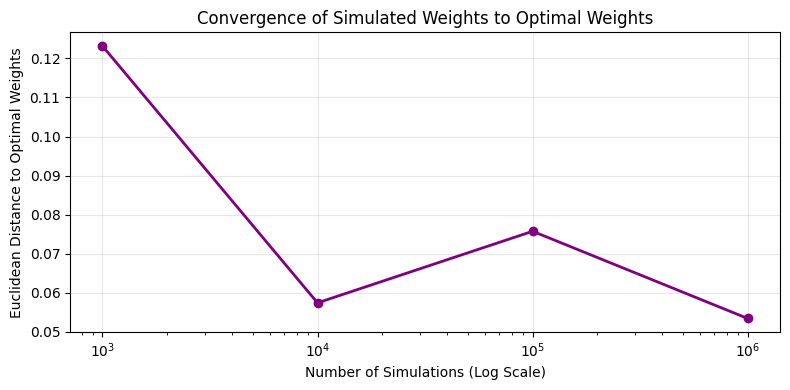

In [ ]:
import numpy as np
import pandas as pd
import cvxpy as cp
from scipy.optimize import minimize
import matplotlib.pyplot as plt
from tqdm import tqdm # For progress bar

# 1. Select the 5 assets
assets_5 = ["TSLA", "WMT", "BAC", "LLY", "XOM"]
idx_5 = [tickers.index(t) for t in assets_5]

# Subset the in-sample data
mu_5 = mu_w[idx_5]
Sigma_5 = Sigma_w[np.ix_(idx_5, idx_5)]
n_5 = len(assets_5)

# 2. Hard Optimization (Max Sharpe, no short-selling)
def neg_sharpe_5(w, mu, Sigma, rf):
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    return -(port_ret - rf) / port_vol

cons_5 = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
bnds_5 = [(0, 1)] * n_5
w0_5 = np.ones(n_5) / n_5

res_5 = minimize(neg_sharpe_5, w0_5, args=(mu_5, Sigma_5, rf_w),
                 method="SLSQP", bounds=bnds_5, constraints=cons_5,
                 options={"ftol": 1e-12, "maxiter": 1000})

w_opt_5 = res_5.x
sharpe_opt_5 = -res_5.fun

print("--- Step 7: Hard Optimization Results (5 Assets) ---")
for t, w in zip(assets_5, w_opt_5):
    print(f"  {t:5s} {w:7.4f}")
print(f"  Max Sharpe Ratio: {sharpe_opt_5:.4f}\n")

# 3. Simulation
# We will test increasing numbers of simulations to see when they converge
sim_counts = [1000, 10000, 100000, 1000000]
results = []

for n_sims in sim_counts:
    np.random.seed(42) # For reproducibility

    # Generate random weights using Dirichlet distribution (sums to 1, all positive)
    # Alpha parameter = 1 gives a uniform distribution over the simplex
    weights_sim = np.random.dirichlet(np.ones(n_5), size=n_sims)

    # Calculate Sharpe for all simulated portfolios at once
    # (N x 5) @ (5 x 5) -> (N x 5), then element-wise multiply with weights and sum
    port_rets_sim = weights_sim @ mu_5
    port_vols_sim = np.sqrt(np.einsum('ij,jk,ik->i', weights_sim, Sigma_5, weights_sim))
    sharpes_sim = (port_rets_sim - rf_w) / port_vols_sim

    # Find the best simulated portfolio
    best_idx = np.argmax(sharpes_sim)
    w_best_sim = weights_sim[best_idx]
    sharpe_best_sim = sharpes_sim[best_idx]

    # Calculate Euclidean distance between optimal and simulated weights
    weight_diff = np.linalg.norm(w_opt_5 - w_best_sim)

    results.append({
        "Simulations": n_sims,
        "Sim_Sharpe": sharpe_best_sim,
        "Optimal_Sharpe": sharpe_opt_5,
        "Weight_Distance": weight_diff
    })

    print(f"Simulations: {n_sims:,.0f} | Best Sim Sharpe: {sharpe_best_sim:.4f} | Weight Distance: {weight_diff:.4f}")

# 4. Plot Convergence
res_df = pd.DataFrame(results)
plt.figure(figsize=(8, 4))
plt.plot(res_df["Simulations"], res_df["Weight_Distance"], marker='o', color='purple', linewidth=2)
plt.xscale('log')
plt.title("Convergence of Simulated Weights to Optimal Weights")
plt.xlabel("Number of Simulations (Log Scale)")
plt.ylabel("Euclidean Distance to Optimal Weights")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Step 8

--- Step 8: Hard Optimization Results (30% Cap) ---
  TSLA   0.1816
  WMT    0.3000
  BAC    0.3000
  LLY    0.1119
  XOM    0.1065
  Max Sharpe Ratio: 0.1318

Target Valid: 10,000 | Actual Evaluated: 2,705 | Sim Sharpe: 0.1303 | Distance: 0.0481 | Acceptance Rate: 5.41%
Target Valid: 100,000 | Actual Evaluated: 27,254 | Sim Sharpe: 0.1310 | Distance: 0.0510 | Acceptance Rate: 5.45%
Target Valid: 1,000,000 | Actual Evaluated: 272,348 | Sim Sharpe: 0.1316 | Distance: 0.0140 | Acceptance Rate: 5.45%
Target Valid: 5,000,000 | Actual Evaluated: 1,362,925 | Sim Sharpe: 0.1316 | Distance: 0.0140 | Acceptance Rate: 5.45%


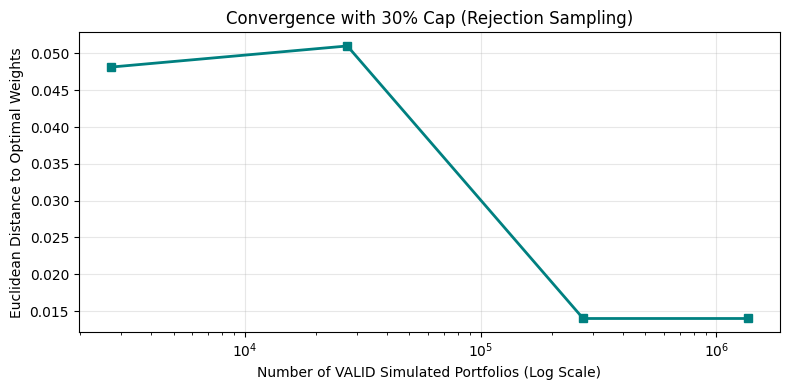

In [ ]:
# ---------- Step 8: 5 Assets, Max Weight 30% ----------

# 1. Hard Optimization with 30% Cap
bnds_30 = [(0, 0.30)] * n_5

res_30 = minimize(neg_sharpe_5, w0_5, args=(mu_5, Sigma_5, rf_w),
                  method="SLSQP", bounds=bnds_30, constraints=cons_5,
                  options={"ftol": 1e-12, "maxiter": 1000})

w_opt_30 = res_30.x
sharpe_opt_30 = -res_30.fun

print("--- Step 8: Hard Optimization Results (30% Cap) ---")
for t, w in zip(assets_5, w_opt_30):
    print(f"  {t:5s} {w:7.4f}")
print(f"  Max Sharpe Ratio: {sharpe_opt_30:.4f}\n")

# 2. Simulation with Rejection Sampling
sim_counts_30 = [10000, 100000, 1000000, 5000000]
results_30 = []

for n_sims in sim_counts_30:
    np.random.seed(42)

    # Generate a massive pool of random weights
    # We generate more than n_sims because we know most will be rejected
    pool_size = n_sims * 5
    weights_pool = np.random.dirichlet(np.ones(n_5), size=pool_size)

    # Rejection: Keep only rows where ALL weights are <= 0.30
    valid_mask = np.all(weights_pool <= 0.30, axis=1)
    weights_valid = weights_pool[valid_mask]

    # If we somehow don't have enough valid weights, we skip (though 5x pool is usually enough)
    if len(weights_valid) == 0:
        print(f"Skipping {n_sims} due to 0 valid weights found.")
        continue

    # Calculate Sharpe for valid portfolios
    port_rets_sim = weights_valid @ mu_5
    port_vols_sim = np.sqrt(np.einsum('ij,jk,ik->i', weights_valid, Sigma_5, weights_valid))
    sharpes_sim = (port_rets_sim - rf_w) / port_vols_sim

    # Find best
    best_idx = np.argmax(sharpes_sim)
    w_best_sim_30 = weights_valid[best_idx]
    sharpe_best_sim_30 = sharpes_sim[best_idx]

    weight_diff_30 = np.linalg.norm(w_opt_30 - w_best_sim_30)

    # Acceptance rate tells us how hard the simulation worked
    acceptance_rate = len(weights_valid) / pool_size

    results_30.append({
        "Target_Valid": n_sims,
        "Actual_Valid": len(weights_valid),
        "Sim_Sharpe": sharpe_best_sim_30,
        "Weight_Distance": weight_diff_30,
        "Acceptance_Rate": acceptance_rate
    })

    print(f"Target Valid: {n_sims:,.0f} | Actual Evaluated: {len(weights_valid):,.0f} | "
          f"Sim Sharpe: {sharpe_best_sim_30:.4f} | Distance: {weight_diff_30:.4f} | "
          f"Acceptance Rate: {acceptance_rate:.2%}")

# 3. Plot Convergence
res_df_30 = pd.DataFrame(results_30)
plt.figure(figsize=(8, 4))
plt.plot(res_df_30["Actual_Valid"], res_df_30["Weight_Distance"], marker='s', color='teal', linewidth=2)
plt.xscale('log')
plt.title("Convergence with 30% Cap (Rejection Sampling)")
plt.xlabel("Number of VALID Simulated Portfolios (Log Scale)")
plt.ylabel("Euclidean Distance to Optimal Weights")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

Part 4, Step 9(a) & 9(b): Synthetic Market Portfolio & Implied Returns

In [ ]:
import yfinance as yf
import numpy as np
import pandas as pd

# 1. Get Market Caps for the 10 assets
mkt_caps = {}
for t in tickers:
    try:
        mkt_caps[t] = yf.Ticker(t).info['marketCap']
    except:
        mkt_caps[t] = 0

total_10_mkt_cap = sum(mkt_caps.values())

# 2. Get Total S&P 500 Market Cap (Proxy)
sp500_total_cap = 40_000_000_000_000

# 3. Calculate Weights
w_10_sp500 = {t: (mkt_caps[t] / sp500_total_cap) for t in tickers}
sum_w_10 = sum(w_10_sp500.values())
w_rest = 1 - sum_w_10

print("--- Market Capitalization Weights ---")
for t in tickers:
    print(f"{t:5s}: {w_10_sp500[t]:.4%}")
print(f"Rest of S&P 500: {w_rest:.4%}")
print(f"Sum of weights: {sum_w_10 + w_rest:.4f}")

# 4. Construct the 11th Asset Returns
sp500_data = yf.download("^GSPC", start="2023-09-01", end="2025-09-30", auto_adjust=True)["Close"]
# Handle potential pandas multi-index from yfinance
if isinstance(sp500_data, pd.DataFrame):
    sp500_data = sp500_data.iloc[:, 0]

sp500_weekly = sp500_data.resample("W-FRI").last().dropna()
sp500_rets = np.log(sp500_weekly).diff().dropna()

# Align the 10 assets returns with S&P 500 returns
rets_aligned = rets.loc[sp500_rets.index]

# Calculate the weighted returns of the 10 assets
w_10_array = np.array([w_10_sp500[t] for t in tickers])
rets_10_weighted = rets_aligned[tickers].values @ w_10_array

# FIX: Convert the numpy array back to a pandas Series with the correct index
rets_10_weighted_series = pd.Series(rets_10_weighted, index=sp500_rets.index)

# Now the subtraction works smoothly
rets_rest_of_sp500 = sp500_rets - rets_10_weighted_series

# 5. Build the 11-Asset Universe
rets_11 = rets_aligned[tickers].copy()
rets_11['REST_SP500'] = rets_rest_of_sp500

# 6. Calculate Mean and Covariance for the 11 assets
mu_11 = rets_11.mean().values * 52 # Annualized
Sigma_11 = rets_11.cov().values * 52 # Annualized

# 7. Black-Litterman Parameters
w_mkt = np.append(w_10_array, w_rest)

# Risk Aversion (delta)
mkt_ret_ann = sp500_rets.mean() * 52
mkt_vol_ann = sp500_rets.std() * np.sqrt(52)
rf_ann = 0.05 # Annual Risk-Free Rate
delta = (mkt_ret_ann - rf_ann) / (mkt_vol_ann**2)

print(f"\nMarket Risk Aversion (delta): {delta:.4f}")

# Implied Equilibrium Returns (Pi)
Pi = delta * Sigma_11 @ w_mkt

print("\n--- Implied Equilibrium Returns (Pi) ---")
for i, t in enumerate(tickers + ["REST"]):
    print(f"{t:5s}: {Pi[i]*100:.2f}%")

# 8. Tau
T = len(rets_11)
tau = 1 / T
print(f"\nTau: {tau:.5f}")

--- Market Capitalization Weights ---
TSLA : 3.9853%
WMT  : 2.4049%
BAC  : 0.8851%
GS   : 0.6753%
LLY  : 3.0611%
MRK  : 0.9026%
GOOG : 8.6319%
META : 3.9920%
AAPL : 12.7301%
XOM  : 1.8842%
Rest of S&P 500: 60.8475%
Sum of weights: 1.0000


[*********************100%***********************]  1 of 1 completed


Market Risk Aversion (delta): 5.8478

--- Implied Equilibrium Returns (Pi) ---
TSLA : 21.80%
WMT  : 6.98%
BAC  : 12.61%
GS   : 14.49%
LLY  : 8.38%
MRK  : 5.15%
GOOG : 12.58%
META : 13.58%
AAPL : 13.58%
XOM  : 3.27%
REST : 5.54%

Tau: 0.00917


Part 4, Step 9(c) & 9(d): Black-Litterman Posterior & Optimization

In [ ]:
# 1. Define the P, Q, and Omega matrices
n_11 = 11
k_views = 3

# P Matrix (3 x 11)
P = np.zeros((k_views, n_11))
# View 1: AAPL returns 18%
P[0, 8] = 1.0
# View 2: LLY outperforms MRK by 5%
P[1, 4] = 1.0
P[1, 5] = -1.0
# View 3: XOM underperforms the REST of the market by 2%
P[2, 9] = 1.0
P[2, 10] = -1.0

# Q Matrix (3 x 1)
Q = np.array([0.18, 0.05, -0.02]).reshape(-1, 1)

# Omega Matrix (3 x 3)
# Using He-Litterman formula: Omega = diag(P * tau * Sigma * P^T)
omega_diag = np.diag(P @ (tau * Sigma_11) @ P.T)
Omega = np.diag(omega_diag)

# 2. Calculate Black-Litterman Posterior Mean (mu_BL) and Covariance (Sigma_BL)
# Formula: mu_BL = [ (tau*Sigma)^-1 + P^T * Omega^-1 * P ]^-1 * [ (tau*Sigma)^-1 * Pi + P^T * Omega^-1 * Q ]
tau_Sigma_inv = np.linalg.inv(tau * Sigma_11)
omega_inv = np.linalg.inv(Omega)

# Calculate the posterior mean
term1 = np.linalg.inv(tau_Sigma_inv + P.T @ omega_inv @ P)
term2 = (tau_Sigma_inv @ Pi.reshape(-1, 1)) + (P.T @ omega_inv @ Q)
mu_BL = term1 @ term2
mu_BL = mu_BL.flatten()

# Calculate the posterior covariance
Sigma_BL = Sigma_11 + term1

print("--- Black-Litterman Posterior Returns (mu_BL) ---")
for i, t in enumerate(tickers + ["REST"]):
    print(f"{t:5s}: {mu_BL[i]*100:.2f}%")

# 3. Optimize the BL Portfolio
# We will optimize the BL portfolio using the same constraints as Step 2:
# Long-only, and max 18% weight (ignoring the REST asset for the 18% cap,
# but for a true BL portfolio, we usually optimize all 11 assets and then extract the 10).
# Let's optimize all 11 assets with a max weight of 18% for the 10, and unrestricted for REST.

def neg_sharpe_BL(w, mu, Sigma, rf):
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    return -(port_ret - rf) / port_vol

# Constraints: sum to 1
cons_BL = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]

# Bounds: 0 to 0.18 for the 10 assets, 0 to 1 for the REST bucket
bnds_BL = [(0, 0.18)] * 10 + [(0, 1.0)]

w0_BL = np.ones(n_11) / n_11

res_BL = minimize(neg_sharpe_BL, w0_BL, args=(mu_BL, Sigma_BL, rf_w),
                  method="SLSQP", bounds=bnds_BL, constraints=cons_BL,
                  options={"ftol": 1e-12, "maxiter": 1000})

w_opt_BL = res_BL.x

print("\n--- Optimized BL Portfolio Weights (18% Cap on 10 Assets) ---")
for i, t in enumerate(tickers + ["REST"]):
    print(f"{t:5s}: {w_opt_BL[i]:.4f}")

# 4. Compare to Step 2 Portfolio
print("\n--- Comparison: Step 2 (Historical MV) vs BL Portfolio ---")
print(f"{'Asset':6s} | {'Step 2':8s} | {'BL':8s}")
print("-" * 26)
for i, t in enumerate(tickers):
    print(f"{t:6s} | {w_step2[i]:7.2%} | {w_opt_BL[i]:7.2%}")

--- Black-Litterman Posterior Returns (mu_BL) ---
TSLA : 23.48%
WMT  : 7.54%
BAC  : 13.36%
GS   : 15.27%
LLY  : 9.49%
MRK  : 5.31%
GOOG : 13.59%
META : 14.45%
AAPL : 15.78%
XOM  : 3.52%
REST : 5.75%

--- Optimized BL Portfolio Weights (18% Cap on 10 Assets) ---
TSLA : 0.0387
WMT  : 0.0217
BAC  : 0.0109
GS   : 0.0128
LLY  : 0.0393
MRK  : 0.0000
GOOG : 0.0833
META : 0.0409
AAPL : 0.1723
XOM  : 0.0224
REST : 0.5577

--- Comparison: Step 2 (Historical MV) vs BL Portfolio ---
Asset  | Step 2   | BL      
--------------------------
TSLA   |   0.00% |   3.87%
WMT    |  18.00% |   2.17%
BAC    |  18.00% |   1.09%
GS     |  18.00% |   1.28%
LLY    |   3.12% |   3.93%
MRK    |  18.00% |   0.00%
GOOG   |   0.00% |   8.33%
META   |   0.00% |   4.09%
AAPL   |  18.00% |  17.23%
XOM    |   6.88% |   2.24%


In [ ]:
import numpy as np
from scipy.optimize import minimize

# Redefine necessary variables just in case
n_11 = 11
k_views = 3

def neg_sharpe_BL(w, mu, Sigma, rf):
    port_ret = mu @ w
    port_vol = np.sqrt(w @ Sigma @ w)
    return -(port_ret - rf) / port_vol

cons_BL = [{"type": "eq", "fun": lambda w: np.sum(w) - 1}]
w0_BL = np.ones(n_11) / n_11

# 1. BL Unconstrained Optimization
# Bounds: 0 to 1 for all 11 assets (REST included)
bnds_BL_unc = [(0, 1.0)] * n_11

res_BL_unc = minimize(neg_sharpe_BL, w0_BL, args=(mu_BL, Sigma_BL, rf_w),
                      method="SLSQP", bounds=bnds_BL_unc, constraints=cons_BL,
                      options={"ftol": 1e-12, "maxiter": 1000})
w_opt_BL_unc = res_BL_unc.x

# 2. BL Constrained Optimization
# Bounds: 0 to 0.18 for the 10 assets, 0 to 1 for REST
bnds_BL_con = [(0, 0.18)] * 10 + [(0, 1.0)]

res_BL_con = minimize(neg_sharpe_BL, w0_BL, args=(mu_BL, Sigma_BL, rf_w),
                      method="SLSQP", bounds=bnds_BL_con, constraints=cons_BL,
                      options={"ftol": 1e-12, "maxiter": 1000})
w_opt_BL = res_BL_con.x

# 3. Print Comparison Table
print(f"{'Asset':8s} | {'P1 Uncon':9s} | {'P1 Con':8s} | {'BL Uncon':9s} | {'BL Con':8s}")
print("-" * 55)
for i, t in enumerate(tickers + ["REST"]):
    p1_unc = w_tangency[i] if i < 10 else 0.0
    p1_con = w_step2[i] if i < 10 else 0.0

    print(f"{t:8s} | {p1_unc:8.2%} | {p1_con:7.2%} | {w_opt_BL_unc[i]:8.2%} | {w_opt_BL[i]:7.2%}")

Asset    | P1 Uncon  | P1 Con   | BL Uncon  | BL Con  
-------------------------------------------------------
TSLA     |    0.00% |   0.00% |    3.87% |   3.87%
WMT      |    0.00% |  18.00% |    2.17% |   2.17%
BAC      |    8.57% |  18.00% |    1.09% |   1.09%
GS       |   35.49% |  18.00% |    1.28% |   1.28%
LLY      |    0.00% |   3.12% |    3.93% |   3.93%
MRK      |   16.45% |  18.00% |    0.00% |   0.00%
GOOG     |    0.00% |   0.00% |    8.33% |   8.33%
META     |    0.00% |   0.00% |    4.09% |   4.09%
AAPL     |   39.49% |  18.00% |   17.23% |  17.23%
XOM      |    0.00% |   6.88% |    2.24% |   2.24%
REST     |    0.00% |   0.00% |   55.77% |  55.77%
